In [19]:
# Install required libraries
!pip install -q imbalanced-learn shap

# Import libraries
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import *
from sklearn.inspection import permutation_importance
from scipy.stats import friedmanchisquare

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:

import pandas as pd

# Load the Dengue dataset from Google Drive
df = pd.read_csv('/content/drive/MyDrive/Dengue dataset.csv')

# Display the first five rows
print("First five rows of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset shape:")
print(df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())


First five rows of the dataset:


,Gender,Age,NS1,IgG,IgM,Area,AreaType,HouseType,District,Fever_Duration,Body_Temperature,Platelet_Count,WBC_Count,Joint_Pain,Headache,Retro_Orbital_Pain,Myalgia,Rash,Outcome
0,Female,45,0,0,0,Mirpur,Undeveloped,Building,Dhaka,2,38.6,129000,8300,Absent,0,0,0,0,0
1,Male,17,0,0,0,Chawkbazar,Developed,Building,Dhaka,4,38.2,325000,7900,Absent,0,0,0,0,0
2,Female,29,0,0,0,Paltan,Undeveloped,Other,Dhaka,6,37.2,309000,6400,Absent,0,0,1,0,0
3,Female,63,1,1,1,Motijheel,Developed,Other,Dhaka,4,39.1,51000,4500,Moderate,1,1,1,1,1
4,Male,22,0,0,0,Gendaria,Undeveloped,Building,Dhaka,4,37.4,185000,9100,Absent,1,0,0,0,0



Dataset shape:
(1000, 19)

Column names:
['Gender', 'Age', 'NS1', 'IgG', 'IgM', 'Area', 'AreaType', 'HouseType', 'District', 'Fever_Duration', 'Body_Temperature', 'Platelet_Count', 'WBC_Count', 'Joint_Pain', 'Headache', 'Retro_Orbital_Pain', 'Myalgia', 'Rash', 'Outcome']


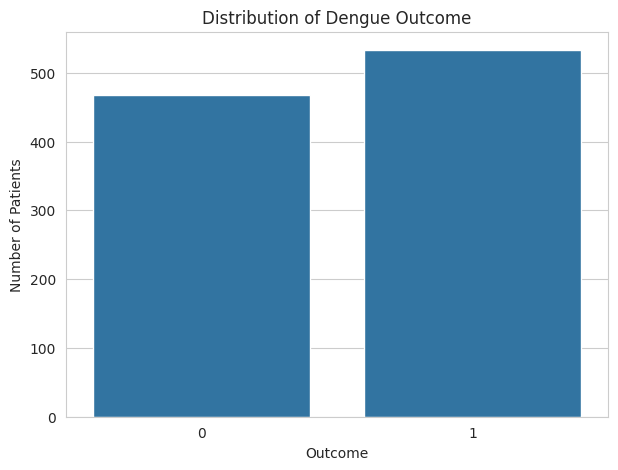

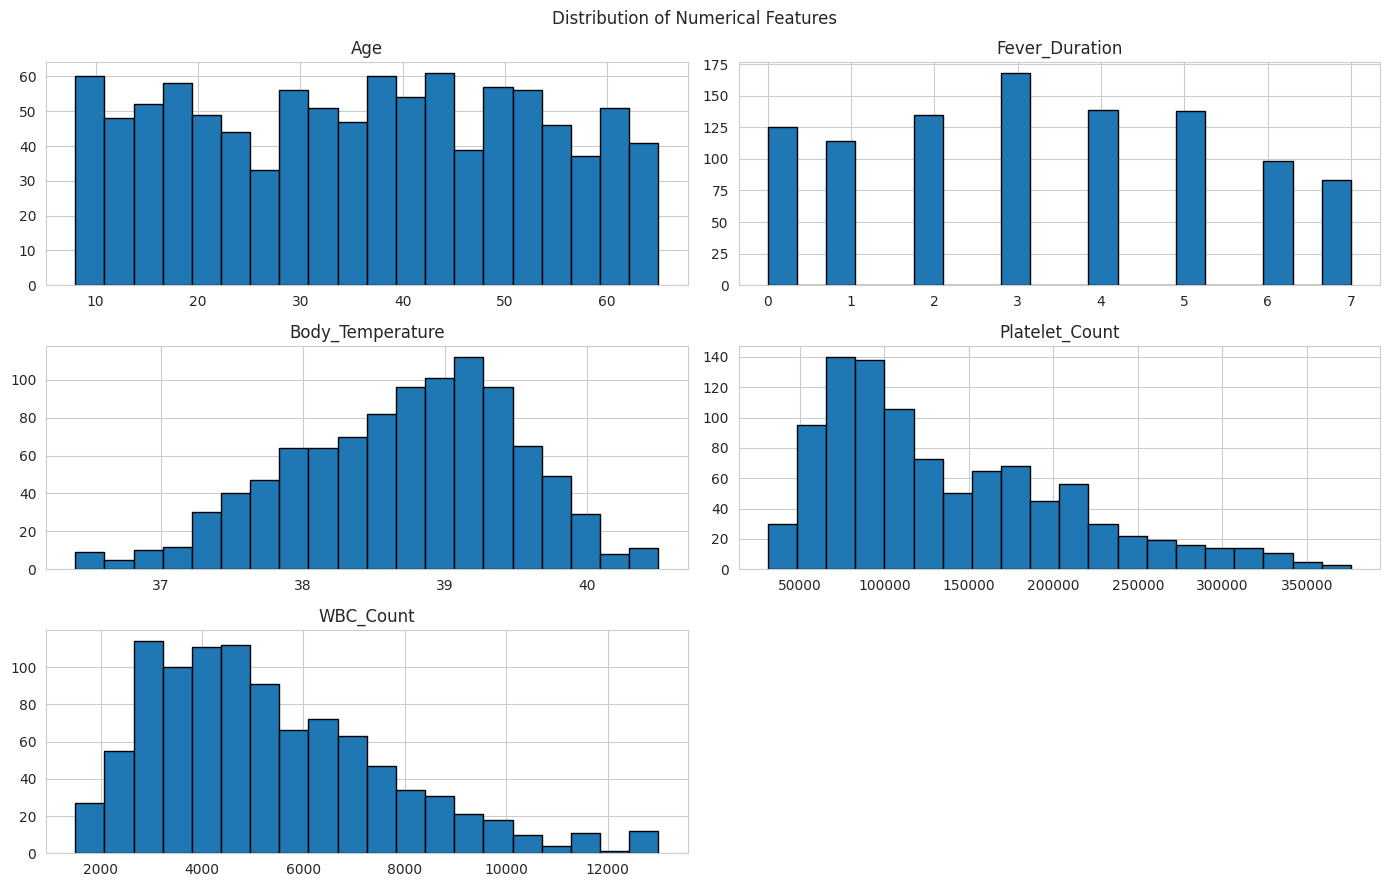

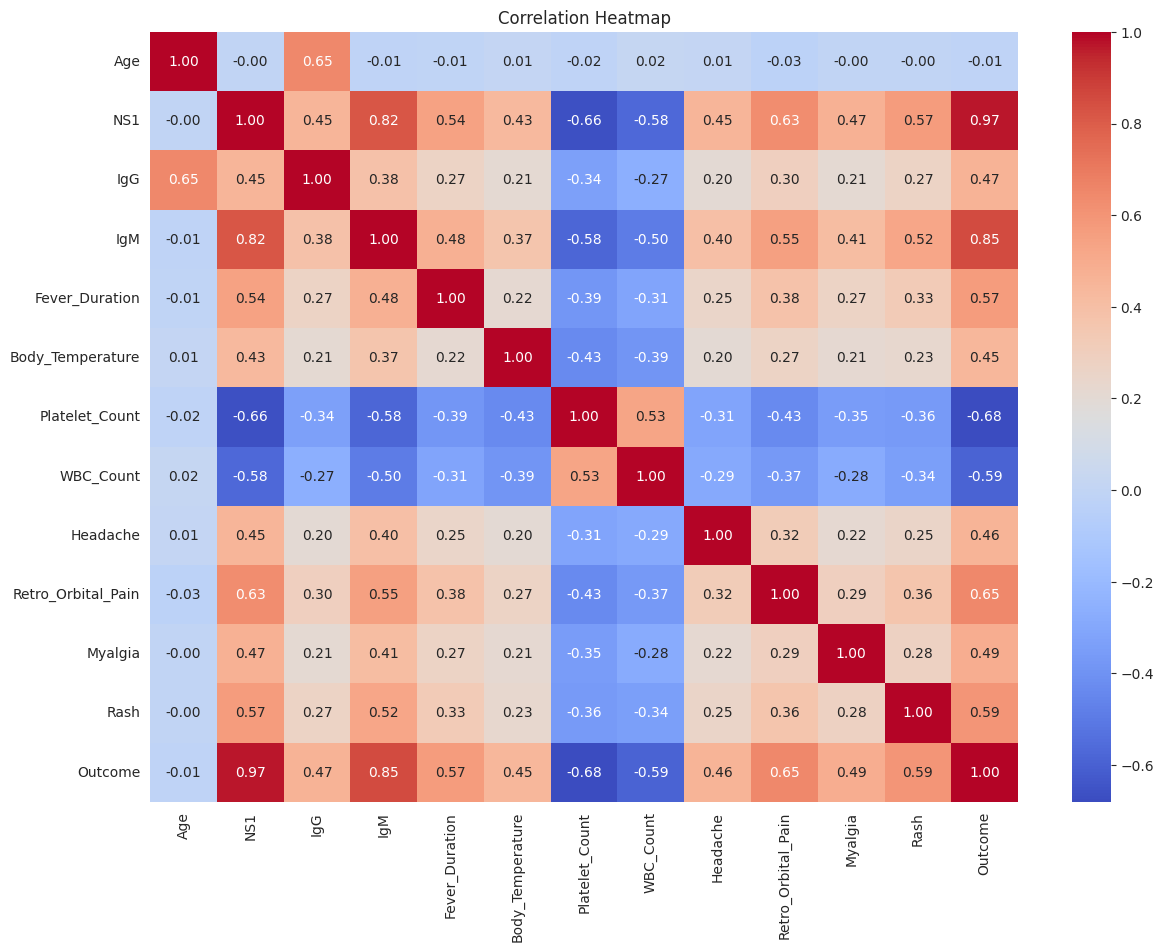

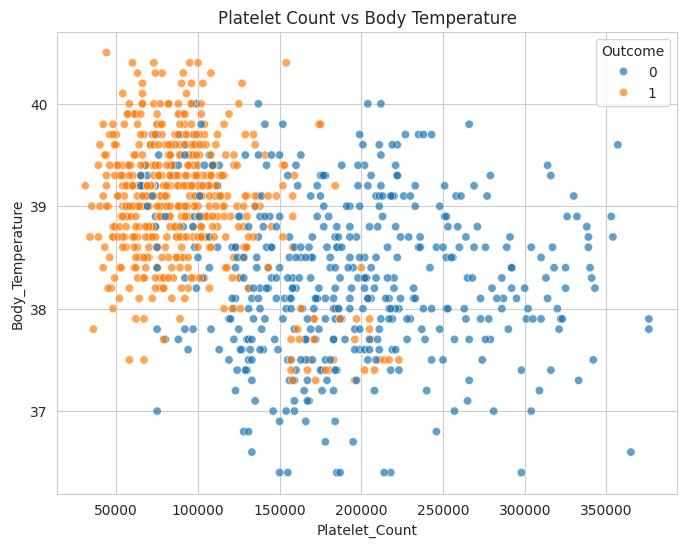

In [22]:
# Set visualization style
sns.set_style("whitegrid")

# 1. Target variable distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Outcome")
plt.title("Distribution of Dengue Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")
plt.show()


# 2. Numerical feature distributions
numeric_columns = [
    "Age",
    "Fever_Duration",
    "Body_Temperature",
    "Platelet_Count",
    "WBC_Count"
]

df[numeric_columns].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()


# 3. Correlation heatmap
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()


# 4. Relationship between platelet count and body temperature
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Platelet_Count",
    y="Body_Temperature",
    hue="Outcome",
    alpha=0.7
)

plt.title("Platelet Count vs Body Temperature")
plt.show()

In [23]:
# Examine diagnostic features against the target

diagnostic_features = ["NS1", "IgG", "IgM"]

for col in diagnostic_features:
    print("\n" + "=" * 45)
    print("Feature:", col)

    print("\nCounts:")
    print(pd.crosstab(df[col], df["Outcome"]))

    print("\nOutcome percentage within each feature value:")
    print(
        pd.crosstab(
            df[col],
            df["Outcome"],
            normalize="index"
        ) * 100
    )


Feature: NS1

Counts:
Outcome    0    1
NS1              
0        467   14
1          0  519

Outcome percentage within each feature value:
Outcome          0           1
NS1                           
0        97.089397    2.910603
1         0.000000  100.000000

Feature: IgG

Counts:
Outcome    0    1
IgG              
0        334  133
1        133  400

Outcome percentage within each feature value:
Outcome          0          1
IgG                          
0        71.520343  28.479657
1        24.953096  75.046904

Feature: IgM

Counts:
Outcome    0    1
IgM              
0        457   68
1         10  465

Outcome percentage within each feature value:
Outcome          0          1
IgM                          
0        87.047619  12.952381
1         2.105263  97.894737


In [24]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove constant and potentially leakage-prone features
columns_to_remove = [
    "District",
    "NS1",
    "IgG",
    "IgM"
]

df_model = df.drop(columns=columns_to_remove)

# Separate input features and target
X = df_model.drop(columns=["Outcome"])
y = df_model["Outcome"]

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Dataset preparation completed")
print("=" * 45)

print("Total records:", len(df_model))
print("Total input features:", X.shape[1])
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Dataset preparation completed
Total records: 1000
Total input features: 14
Numerical features: ['Age', 'Fever_Duration', 'Body_Temperature', 'Platelet_Count', 'WBC_Count', 'Headache', 'Retro_Orbital_Pain', 'Myalgia', 'Rash']
Categorical features: ['Gender', 'Area', 'AreaType', 'HouseType', 'Joint_Pain']

Training set: (800, 14)
Testing set: (200, 14)

Training target distribution:
Outcome
1    426
0    374
Name: count, dtype: int64

Testing target distribution:
Outcome
1    107
0     93
Name: count, dtype: int64


In [25]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data without fitting again
X_test_processed = preprocessor.transform(X_test)

# Display results
print("PREPROCESSING COMPLETED")
print("=" * 45)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train_processed).sum())
print("Testing:", np.isnan(X_test_processed).sum())

PREPROCESSING COMPLETED
Original training shape: (800, 14)
Processed training shape: (800, 55)
Original testing shape: (200, 14)
Processed testing shape: (200, 55)

Missing values after preprocessing:
Training: 0
Testing: 0


In [26]:
# Define machine learning models

models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    ),

    "Multi-Layer Perceptron": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42
    )
}

# Display model names
print("MACHINE LEARNING MODELS")
print("=" * 45)

for i, model_name in enumerate(models.keys(), start=1):
    print(f"{i}. {model_name}")

print("\nTotal models:", len(models))

MACHINE LEARNING MODELS
1. Dummy Classifier
2. Logistic Regression
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine
6. Decision Tree
7. Random Forest
8. Extra Trees
9. Gradient Boosting
10. AdaBoost
11. Multi-Layer Perceptron

Total models: 11


In [27]:
# Train all models and evaluate initial performance

trained_models = {}
initial_results = []

for name, model in models.items():

    start_time = time.time()

    # Train model
    model.fit(X_train_processed, y_train)

    training_time = time.time() - start_time

    # Predict on testing data
    y_pred = model.predict(X_test_processed)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    initial_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (s)": training_time
    })

    trained_models[name] = model

    print(f"{name} completed!")

# Create comparison table
initial_results_df = pd.DataFrame(initial_results)

print("\nINITIAL MODEL PERFORMANCE")
display(
    initial_results_df.sort_values(
        by="F1-Score",
        ascending=False
    ).round(4)
)

Dummy Classifier completed!
Logistic Regression completed!
K-Nearest Neighbors completed!
Gaussian Naive Bayes completed!
Support Vector Machine completed!
Decision Tree completed!
Random Forest completed!
Extra Trees completed!
Gradient Boosting completed!
AdaBoost completed!
Multi-Layer Perceptron completed!

INITIAL MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (s)
9,AdaBoost,0.985,0.9815,0.9907,0.9860,0.3405
6,Random Forest,0.980,0.9725,0.9907,0.9815,1.1667
1,Logistic Regression,0.980,0.9725,0.9907,0.9815,0.0240
4,Support Vector Machine,0.975,0.9636,0.9907,0.9770,0.1046
2,K-Nearest Neighbors,0.975,0.9636,0.9907,0.9770,0.0013
8,Gradient Boosting,0.975,0.9811,0.9720,0.9765,0.7038
10,Multi-Layer Perceptron,0.970,0.9550,0.9907,0.9725,2.8949
7,Extra Trees,0.965,0.9464,0.9907,0.9680,1.0340
5,Decision Tree,0.935,0.9434,0.9346,0.9390,0.0071
3,Gaussian Naive Bayes,0.880,0.8547,0.9346,0.8929,0.0039


In [28]:
from scipy.stats import randint

# Models to tune (Dummy Classifier is our baseline)
tuning_models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        {
            "model__C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 15],
            "model__weights": ["uniform", "distance"]
        }
    ),

    "Gaussian Naive Bayes": (
        GaussianNB(),
        {
            "model__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
        }
    ),

    "Support Vector Machine": (
        SVC(probability=True, random_state=42),
        {
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", "auto"],
            "model__kernel": ["rbf", "linear"]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [None, 5, 10, 15, 20],
            "model__min_samples_split": [2, 5, 10],
            "model__criterion": ["gini", "entropy"]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [None, 5, 10, 15],
            "model__min_samples_split": [2, 5, 10]
        }
    ),

    "Extra Trees": (
        ExtraTreesClassifier(random_state=42),
        {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [None, 5, 10, 15],
            "model__min_samples_split": [2, 5, 10]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__n_estimators": [100, 150, 200],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__max_depth": [2, 3, 5]
        }
    ),

    "AdaBoost": (
        AdaBoostClassifier(random_state=42),
        {
            "model__n_estimators": [50, 100, 150, 200],
            "model__learning_rate": [0.01, 0.05, 0.1, 1.0]
        }
    ),

    "Multi-Layer Perceptron": (
        MLPClassifier(max_iter=500, random_state=42),
        {
            "model__hidden_layer_sizes": [(50,), (100,), (100, 50)],
            "model__alpha": [0.0001, 0.001, 0.01],
            "model__learning_rate_init": [0.001, 0.01]
        }
    )
}

# Cross-validation configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuned_models = {}
tuning_results = []

# Tune each model
for name, (model, parameters) in tuning_models.items():

    print("\nTuning:", name)

    # Complete pipeline prevents preprocessing leakage
    pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=8,
        scoring="f1_macro",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=0
    )

    start_time = time.time()

    search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Macro F1": search.best_score_,
        "Best Parameters": search.best_params_,
        "Tuning Time (s)": elapsed_time
    })

    print("Best CV Macro F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

# Display tuning results
tuning_results_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER TUNING SUMMARY")

display(
    tuning_results_df[
        ["Model", "Best CV Macro F1", "Tuning Time (s)"]
    ].sort_values(
        by="Best CV Macro F1",
        ascending=False
    ).round(4)
)


Tuning: Logistic Regression
Best CV Macro F1: 0.9799
Best parameters: {'model__C': 1}

Tuning: K-Nearest Neighbors
Best CV Macro F1: 0.9774
Best parameters: {'model__weights': 'distance', 'model__n_neighbors': 11}

Tuning: Gaussian Naive Bayes
Best CV Macro F1: 0.888
Best parameters: {'model__var_smoothing': 1e-09}

Tuning: Support Vector Machine
Best CV Macro F1: 0.9787
Best parameters: {'model__kernel': 'linear', 'model__gamma': 'scale', 'model__C': 0.1}

Tuning: Decision Tree
Best CV Macro F1: 0.9285
Best parameters: {'model__min_samples_split': 2, 'model__max_depth': 15, 'model__criterion': 'gini'}

Tuning: Random Forest
Best CV Macro F1: 0.9761
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__max_depth': 5}

Tuning: Extra Trees
Best CV Macro F1: 0.9635
Best parameters: {'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__max_depth': 10}

Tuning: Gradient Boosting
Best CV Macro F1: 0.9749
Best parameters: {'model__n_estimators': 

,Model,Best CV Macro F1,Tuning Time (s)
9,Multi-Layer Perceptron,0.9824,17.0216
0,Logistic Regression,0.9799,9.6414
3,Support Vector Machine,0.9787,4.6926
1,K-Nearest Neighbors,0.9774,2.3736
5,Random Forest,0.9761,27.2408
7,Gradient Boosting,0.9749,20.7845
8,AdaBoost,0.9698,13.2820
6,Extra Trees,0.9635,13.8770
4,Decision Tree,0.9285,5.0963
2,Gaussian Naive Bayes,0.8880,1.3437


In [29]:
# Evaluate tuned models on the untouched test set

final_results = []
final_models = {}

for name, model in tuned_models.items():

    # Measure training time
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    y_pred = model.predict(X_test)
    inference_time = time.time() - start_time

    # Prediction probabilities
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate metrics
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    })

    final_models[name] = model

# Add Dummy Classifier baseline
dummy_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

dummy_pipeline.fit(X_train, y_train)

y_dummy_pred = dummy_pipeline.predict(X_test)
y_dummy_prob = dummy_pipeline.predict_proba(X_test)[:, 1]

final_results.append({
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y_test, y_dummy_pred),
    "Macro Precision": precision_score(
        y_test, y_dummy_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_dummy_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_dummy_pred, average="macro"
    ),
    "Weighted F1": f1_score(
        y_test, y_dummy_pred, average="weighted"
    ),
    "MCC": matthews_corrcoef(y_test, y_dummy_pred),
    "ROC-AUC": roc_auc_score(y_test, y_dummy_prob),
    "PR-AUC": average_precision_score(y_test, y_dummy_prob),
    "Training Time (s)": np.nan,
    "Inference Time (s)": np.nan
})

# Create final comparison table
final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE")
display(final_results_df.round(4))

# Save results
final_results_df.to_csv(
    "final_model_results.csv",
    index=False
)

print("\nResults saved as final_model_results.csv")

FINAL MODEL PERFORMANCE


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,MCC,ROC-AUC,PR-AUC,Training Time (s),Inference Time (s)
0,Gradient Boosting,0.990,0.9908,0.9892,0.9899,0.9900,0.9801,0.9988,0.9989,0.7005,0.0121
1,AdaBoost,0.985,0.9853,0.9846,0.9849,0.9850,0.9699,0.9993,0.9994,0.4359,0.0454
2,Logistic Regression,0.980,0.9807,0.9792,0.9799,0.9800,0.9599,0.9994,0.9995,0.0321,0.0102
3,Support Vector Machine,0.980,0.9807,0.9792,0.9799,0.9800,0.9599,0.9989,0.9991,0.0385,0.0081
4,K-Nearest Neighbors,0.980,0.9807,0.9792,0.9799,0.9800,0.9599,0.9978,0.9981,0.0197,0.0145
5,Random Forest,0.980,0.9807,0.9792,0.9799,0.9800,0.9599,0.9984,0.9986,0.4219,0.0278
6,Multi-Layer Perceptron,0.975,0.9763,0.9738,0.9748,0.9750,0.9501,0.9983,0.9985,4.3932,0.0104
7,Extra Trees,0.970,0.9719,0.9684,0.9698,0.9699,0.9403,0.9968,0.9974,0.5821,0.0561
8,Decision Tree,0.935,0.9345,0.9350,0.9347,0.9350,0.8695,0.9350,0.9167,0.0184,0.0080
9,Gaussian Naive Bayes,0.880,0.8852,0.8759,0.8782,0.8793,0.7610,0.9373,0.9298,0.0175,0.0078



Results saved as final_model_results.csv


In [30]:
display(final_results_df.to_string(index=False))

'                 Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1      MCC  ROC-AUC   PR-AUC  Training Time (s)  Inference Time (s)\n     Gradient Boosting     0.990         0.990826      0.989247  0.989936     0.989992 0.980072 0.998794 0.998947           0.700495            0.012100\n              AdaBoost     0.985         0.985306      0.984574  0.984915     0.984994 0.969880 0.999297 0.999391           0.435945            0.045376\n   Logistic Regression     0.980         0.980744      0.979198  0.979871     0.979984 0.959941 0.999397 0.999490           0.032093            0.010194\nSupport Vector Machine     0.980         0.980744      0.979198  0.979871     0.979984 0.959941 0.998895 0.999069           0.038514            0.008098\n   K-Nearest Neighbors     0.980         0.980744      0.979198  0.979871     0.979984 0.959941 0.997789 0.998076           0.019730            0.014496\n         Random Forest     0.980         0.980744      0.979198  0.979871  

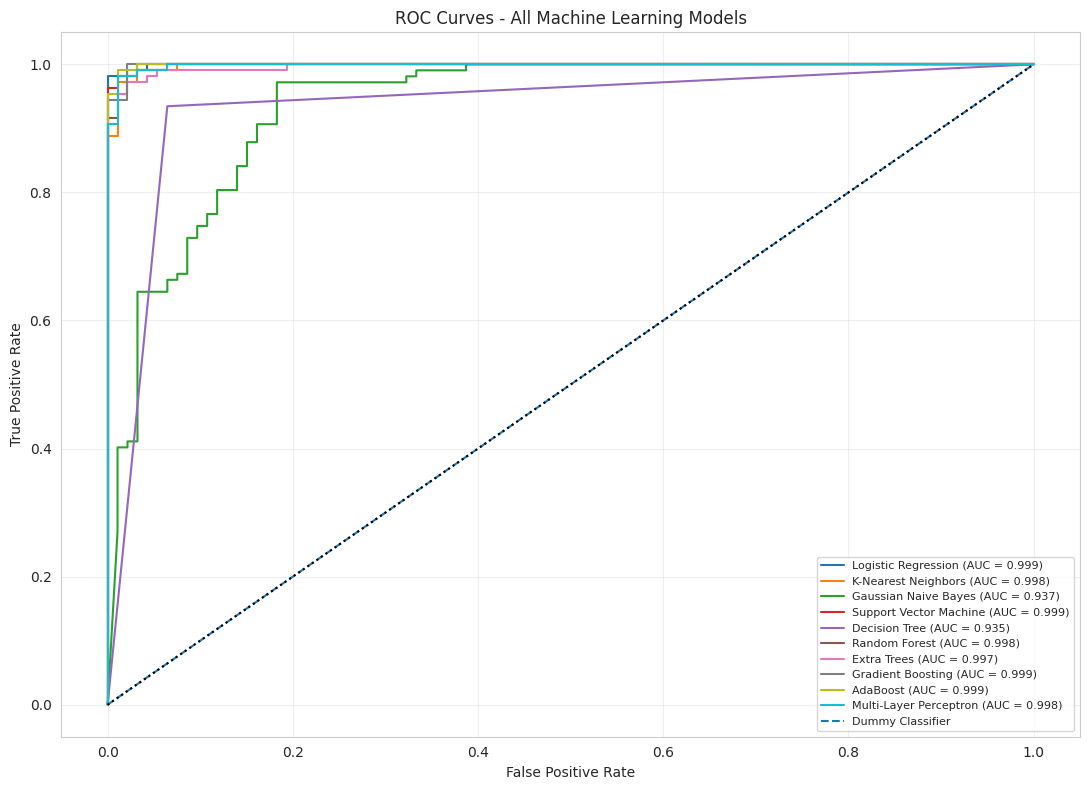

In [31]:
plt.figure(figsize=(11, 8))

for name, model in final_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Dummy baseline
dummy_fpr, dummy_tpr, _ = roc_curve(y_test, y_dummy_prob)

plt.plot(
    dummy_fpr,
    dummy_tpr,
    linestyle="--",
    label="Dummy Classifier"
)

plt.plot([0, 1], [0, 1], linestyle=":", color="black")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Machine Learning Models")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

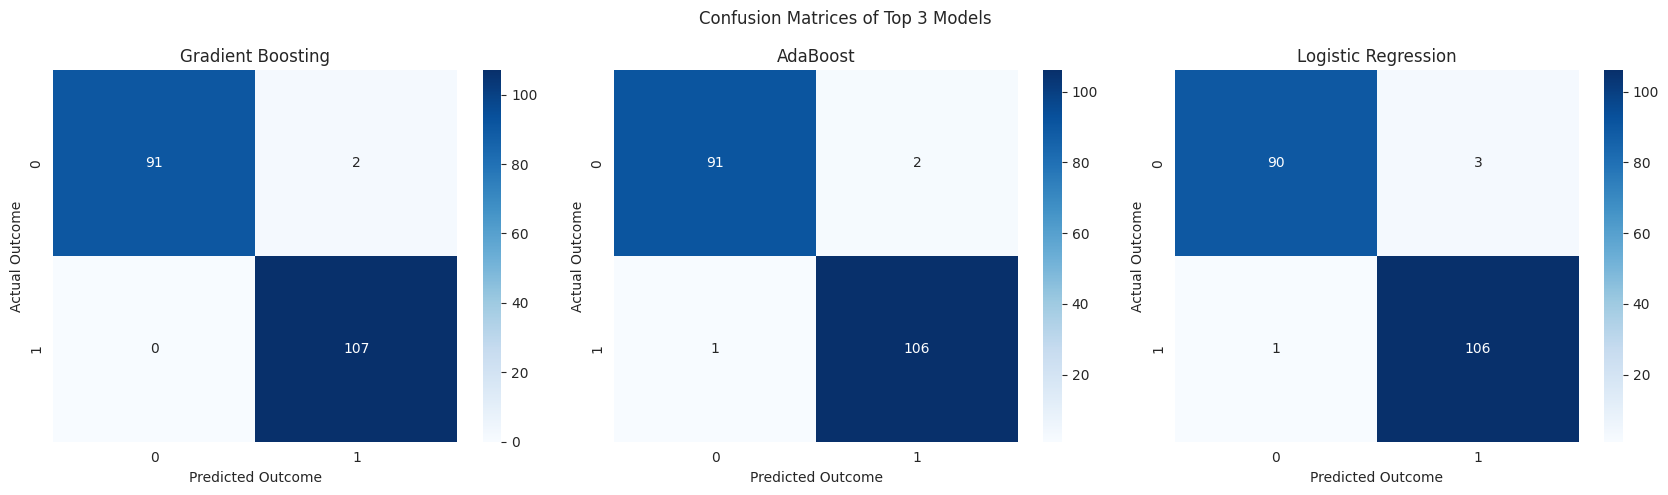

Top 3 models: ['Gradient Boosting', 'AdaBoost', 'Logistic Regression']


In [32]:
# Select top 3 models based on Macro F1
top_3_models = final_results_df[
    final_results_df["Model"] != "Dummy Classifier"
].head(3)["Model"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, name in zip(axes, top_3_models):

    model = final_models[name]

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["0", "1"],
        yticklabels=["0", "1"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

plt.suptitle("Confusion Matrices of Top 3 Models")
plt.tight_layout()
plt.show()

print("Top 3 models:", top_3_models)

TOP 14 FEATURE IMPORTANCE


,Feature,Importance,Std
7,Platelet_Count,0.06117,0.01251
11,Retro_Orbital_Pain,0.03864,0.00950
13,Rash,0.03727,0.01122
9,Joint_Pain,0.03600,0.00919
5,Fever_Duration,0.03496,0.01013
8,WBC_Count,0.00979,0.00735
10,Headache,0.00502,0.00275
12,Myalgia,0.00428,0.00329
6,Body_Temperature,0.00176,0.00287
2,Area,0.00126,0.00218


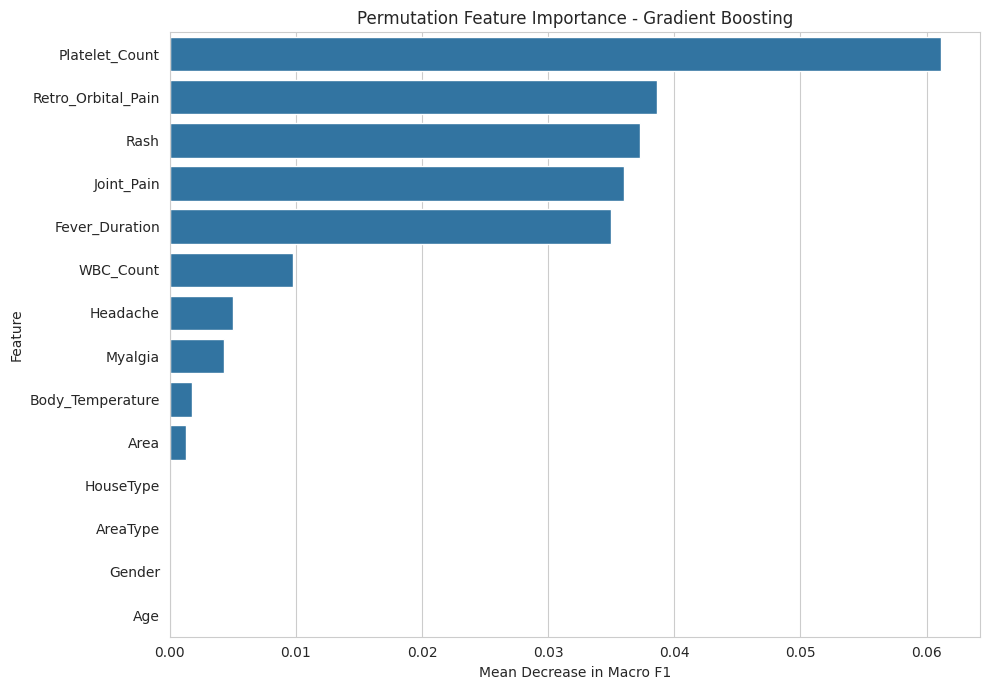

In [33]:
# Permutation feature importance
best_model = final_models["Gradient Boosting"]

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Create importance dataframe
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 14 FEATURE IMPORTANCE")
display(importance_df.round(5))

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance - Gradient Boosting")
plt.xlabel("Mean Decrease in Macro F1")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Save results
importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

In [34]:
from scipy.stats import binomtest

# Select top 3 models
top_3_models = final_results_df[
    final_results_df["Model"] != "Dummy Classifier"
].head(3)["Model"].tolist()

# Generate predictions
predictions = {}

for name in top_3_models:
    predictions[name] = final_models[name].predict(X_test)

# 1. Error analysis for the best model
best_name = top_3_models[0]
best_predictions = predictions[best_name]

error_mask = best_predictions != y_test.to_numpy()

errors = X_test.loc[error_mask].copy()
errors["Actual_Outcome"] = y_test.loc[errors.index]
errors["Predicted_Outcome"] = best_predictions[error_mask]

print("ERROR ANALYSIS")
print("=" * 50)
print("Best model:", best_name)
print("Total test records:", len(y_test))
print("Misclassified records:", error_mask.sum())
print("Correctly classified records:", (~error_mask).sum())

display(errors)

# Save errors
errors.to_csv("misclassified_cases.csv", index=False)

# 2. McNemar exact test: best model vs other top models
print("\nMcNEMAR STATISTICAL TEST")
print("=" * 50)

for other_name in top_3_models[1:]:

    pred_best = predictions[best_name]
    pred_other = predictions[other_name]

    correct_best = pred_best == y_test.to_numpy()
    correct_other = pred_other == y_test.to_numpy()

    # Discordant prediction counts
    b = np.sum(correct_best & ~correct_other)
    c = np.sum(~correct_best & correct_other)

    # Exact McNemar test
    p_value = binomtest(
        min(b, c),
        n=b + c,
        p=0.5,
        alternative="two-sided"
    ).pvalue if (b + c) > 0 else 1.0

    print(f"\n{best_name} vs {other_name}")
    print("Best model alone correct:", b)
    print("Other model alone correct:", c)
    print("Exact McNemar p-value:", round(p_value, 5))

    if p_value < 0.05:
        print("Result: Statistically significant difference")
    else:
        print("Result: No statistically significant difference")

ERROR ANALYSIS
Best model: Gradient Boosting
Total test records: 200
Misclassified records: 2
Correctly classified records: 198


,Gender,Age,Area,AreaType,HouseType,Fever_Duration,Body_Temperature,Platelet_Count,WBC_Count,Joint_Pain,Headache,Retro_Orbital_Pain,Myalgia,Rash,Actual_Outcome,Predicted_Outcome
120,Male,57,Bosila,Undeveloped,Tinshed,3,39.3,69000,2900,Moderate,1,0,0,0,0,1
993,Female,15,Kadamtali,Developed,Other,5,37.7,122000,7100,Moderate,1,0,0,1,0,1



McNEMAR STATISTICAL TEST

Gradient Boosting vs AdaBoost
Best model alone correct: 1
Other model alone correct: 0
Exact McNemar p-value: 1.0
Result: No statistically significant difference

Gradient Boosting vs Logistic Regression
Best model alone correct: 2
Other model alone correct: 0
Exact McNemar p-value: 0.5
Result: No statistically significant difference


In [35]:
# Add feature selection to the tuning pipeline

tuned_models = {}
tuning_results = []

for name, (model, parameters) in tuning_models.items():

    print("\nTuning:", name)

    pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("feature_select", SelectKBest(
            score_func=f_classif,
            k=20
        )),
        ("model", model)
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=8,
        scoring="f1_macro",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=0
    )

    start_time = time.time()

    search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV Macro F1": search.best_score_,
        "Best Parameters": search.best_params_,
        "Tuning Time (s)": elapsed_time
    })

    print("Best CV Macro F1:", round(search.best_score_, 4))

tuning_results_df = pd.DataFrame(tuning_results)

print("\nUPDATED TUNING RESULTS")

display(
    tuning_results_df[
        ["Model", "Best CV Macro F1", "Tuning Time (s)"]
    ].sort_values(
        by="Best CV Macro F1",
        ascending=False
    ).round(4)
)


Tuning: Logistic Regression
Best CV Macro F1: 0.9799

Tuning: K-Nearest Neighbors
Best CV Macro F1: 0.9774

Tuning: Gaussian Naive Bayes
Best CV Macro F1: 0.9145

Tuning: Support Vector Machine
Best CV Macro F1: 0.9812

Tuning: Decision Tree
Best CV Macro F1: 0.9385

Tuning: Random Forest
Best CV Macro F1: 0.9761

Tuning: Extra Trees
Best CV Macro F1: 0.9698

Tuning: Gradient Boosting
Best CV Macro F1: 0.9774

Tuning: AdaBoost
Best CV Macro F1: 0.9749

Tuning: Multi-Layer Perceptron
Best CV Macro F1: 0.9749

UPDATED TUNING RESULTS


,Model,Best CV Macro F1,Tuning Time (s)
3,Support Vector Machine,0.9812,2.4989
0,Logistic Regression,0.9799,0.7995
1,K-Nearest Neighbors,0.9774,1.1441
7,Gradient Boosting,0.9774,17.3308
5,Random Forest,0.9761,16.6542
9,Multi-Layer Perceptron,0.9749,20.4304
8,AdaBoost,0.9749,13.3328
6,Extra Trees,0.9698,12.3640
4,Decision Tree,0.9385,1.9083
2,Gaussian Naive Bayes,0.9145,0.6641


In [36]:
print("Current top 3 models:")
print(final_results_df[["Model", "Macro F1", "Accuracy"]].head(3))

print("\nAvailable final models:")
print(list(final_models.keys()))

Current top 3 models:
                 Model  Macro F1  Accuracy
0    Gradient Boosting  0.989936     0.990
1             AdaBoost  0.984915     0.985
2  Logistic Regression  0.979871     0.980

Available final models:
['Logistic Regression', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Support Vector Machine', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'AdaBoost', 'Multi-Layer Perceptron']


Generating confusion matrices for: ['Gradient Boosting', 'AdaBoost', 'Logistic Regression']


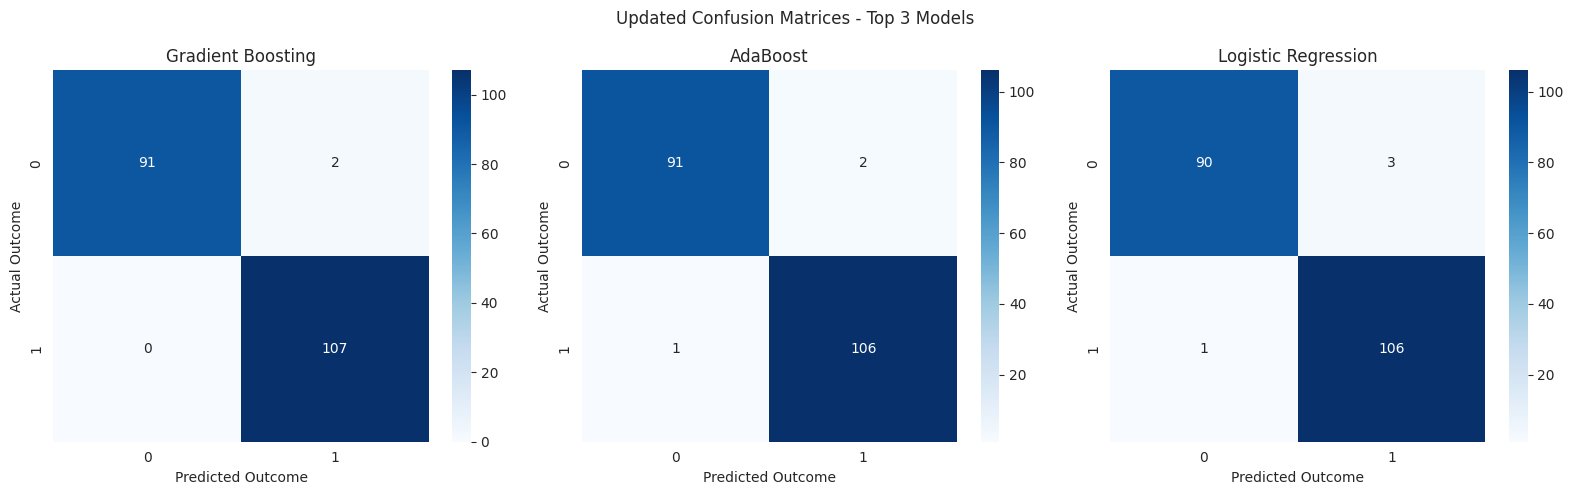

In [37]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get the current top 3 models
top_3_models = final_results_df.head(3)["Model"].tolist()

print("Generating confusion matrices for:", top_3_models)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model_name in zip(axes, top_3_models):
    model = final_models[model_name]
    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=[0, 1],
        yticklabels=[0, 1]
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Outcome")
    ax.set_ylabel("Actual Outcome")

plt.suptitle("Updated Confusion Matrices - Top 3 Models")
plt.tight_layout()
plt.show()

Feature Importance - AdaBoost


,Feature,Importance,Std
7,Platelet_Count,0.064036,0.014702
11,Retro_Orbital_Pain,0.046224,0.008357
13,Rash,0.042136,0.008438
9,Joint_Pain,0.039764,0.005766
5,Fever_Duration,0.028676,0.008436
12,Myalgia,0.015590,0.004737
8,WBC_Count,0.008024,0.007514
10,Headache,0.007526,0.004057
6,Body_Temperature,0.001513,0.002311
2,Area,0.000499,0.002704


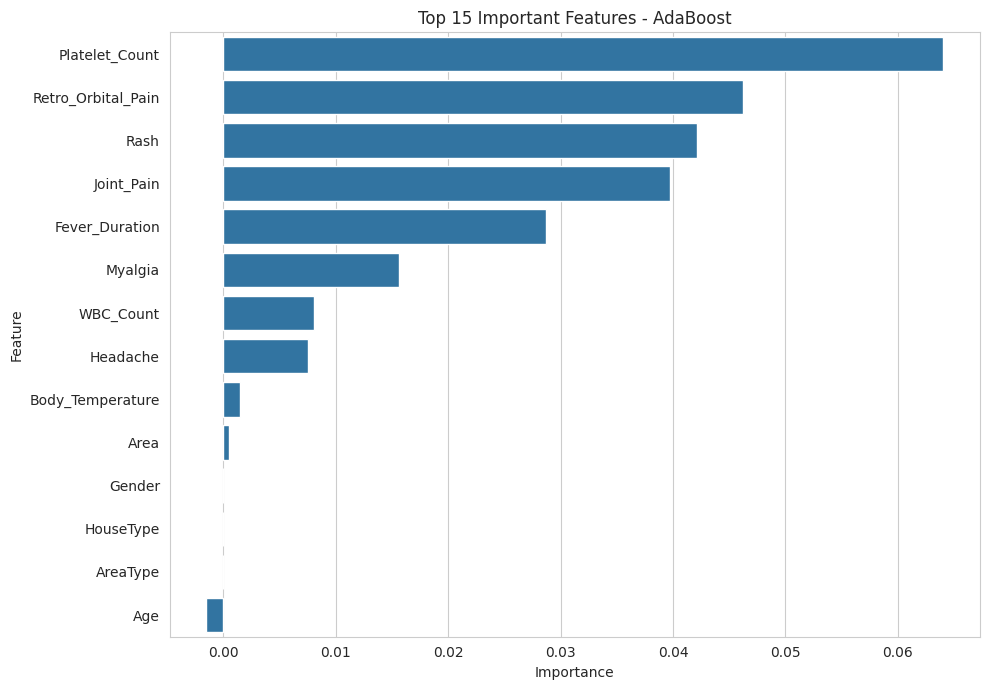

In [38]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select the best model
best_model = final_models["AdaBoost"]

# Calculate permutation importance
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance - AdaBoost")
display(importance_df)

# Plot top 15 features
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - AdaBoost")
plt.tight_layout()
plt.show()

In [39]:
from scipy.stats import binomtest
import pandas as pd

# Current top 3 models
top_3 = final_results_df.head(3)["Model"].tolist()

# Generate predictions
predictions = {
    name: final_models[name].predict(X_test)
    for name in top_3
}

# 1. Error analysis for AdaBoost
best_name = "AdaBoost"
best_predictions = predictions[best_name]

error_mask = best_predictions != y_test.values

error_analysis = X_test.loc[error_mask].copy()
error_analysis["Actual"] = y_test.loc[error_mask]
error_analysis["Predicted"] = best_predictions[error_mask]

print("AdaBoost Error Analysis")
print("Total errors:", error_mask.sum())
display(error_analysis)

# 2. Exact McNemar test using paired predictions
print("\nMcNemar Exact Tests")

for other_name in top_3:
    if other_name == best_name:
        continue

    best_correct = best_predictions == y_test.values
    other_correct = predictions[other_name] == y_test.values

    b = sum(best_correct & ~other_correct)
    c = sum(~best_correct & other_correct)

    if b + c == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            min(b, c),
            n=b + c,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    print(f"\n{best_name} vs {other_name}")
    print("AdaBoost correct, other wrong:", b)
    print("AdaBoost wrong, other correct:", c)
    print("Exact McNemar p-value:", round(p_value, 4))

AdaBoost Error Analysis
Total errors: 3


,Gender,Age,Area,AreaType,HouseType,Fever_Duration,Body_Temperature,Platelet_Count,WBC_Count,Joint_Pain,Headache,Retro_Orbital_Pain,Myalgia,Rash,Actual,Predicted
72,Female,45,Kamrangirchar,Undeveloped,Tinshed,2,37.5,211000,6300,Severe,1,1,0,0,1,0
120,Male,57,Bosila,Undeveloped,Tinshed,3,39.3,69000,2900,Moderate,1,0,0,0,0,1
993,Female,15,Kadamtali,Developed,Other,5,37.7,122000,7100,Moderate,1,0,0,1,0,1



McNemar Exact Tests

AdaBoost vs Gradient Boosting
AdaBoost correct, other wrong: 0
AdaBoost wrong, other correct: 1
Exact McNemar p-value: 1.0

AdaBoost vs Logistic Regression
AdaBoost correct, other wrong: 1
AdaBoost wrong, other correct: 0
Exact McNemar p-value: 1.0


In [40]:
from sklearn.model_selection import cross_val_score
import pandas as pd

cv_results = []

for name, model in final_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV Macro F1 Mean": scores.mean(),
        "CV Macro F1 Std": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="CV Macro F1 Mean",
    ascending=False
)

print("Five-Fold Cross-Validation Results")
display(cv_results_df.round(4))

cv_results_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

Five-Fold Cross-Validation Results


,Model,CV Macro F1 Mean,CV Macro F1 Std
9,Multi-Layer Perceptron,0.9824,0.0092
0,Logistic Regression,0.9799,0.0108
3,Support Vector Machine,0.9787,0.0094
1,K-Nearest Neighbors,0.9774,0.0085
5,Random Forest,0.9761,0.0122
7,Gradient Boosting,0.9749,0.0105
8,AdaBoost,0.9698,0.0109
6,Extra Trees,0.9635,0.0184
4,Decision Tree,0.9285,0.0142
2,Gaussian Naive Bayes,0.8880,0.0324


In [41]:
from google.colab import files

files.download("final_model_results.csv")
files.download("cross_validation_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
# Outlier analysis using the IQR method

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns

outlier_results = []

for col in numerical_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": outliers,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound
    })

outlier_df = pd.DataFrame(outlier_results)

print("Outlier Analysis (Training Data)")
display(outlier_df.round(2))

Outlier Analysis (Training Data)


,Feature,Outlier Count,Lower Bound,Upper Bound
0,Age,0,-20.0,92.0
1,Fever_Duration,0,-2.5,9.5
2,Body_Temperature,0,36.3,41.1
3,Platelet_Count,10,-72000.0,336000.0
4,WBC_Count,12,-1450.0,11750.0
5,Headache,0,-1.5,2.5
6,Retro_Orbital_Pain,0,-1.5,2.5
7,Myalgia,0,-1.5,2.5
8,Rash,0,-1.5,2.5


In [43]:
outlier_df.to_csv("outlier_analysis.csv", index=False)

from google.colab import files
files.download("outlier_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

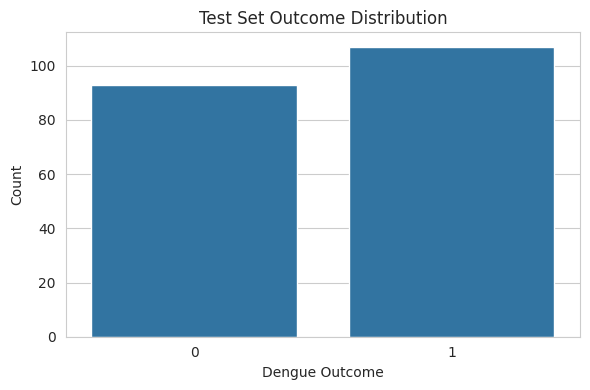

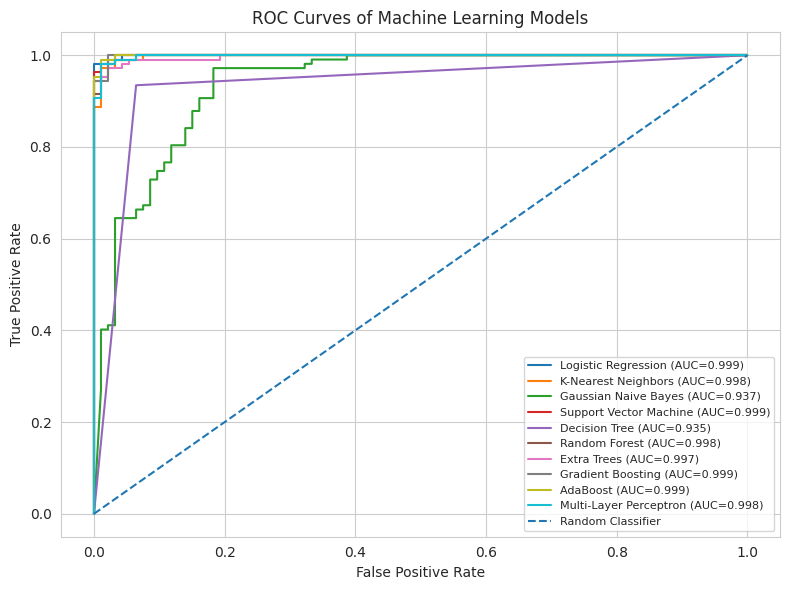

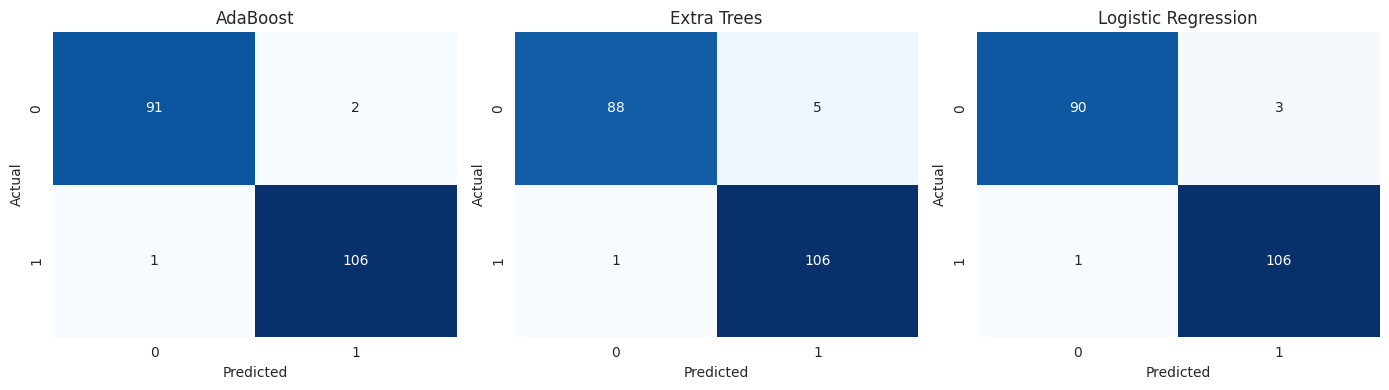

ROC and confusion matrix figures saved.


In [44]:

import os
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    roc_curve,
    auc
)

# Create folder for paper figures
os.makedirs("paper_figures", exist_ok=True)

# 1. Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y_test)
plt.title("Test Set Outcome Distribution")
plt.xlabel("Dengue Outcome")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("paper_figures/target_distribution.png", dpi=300)
plt.show()
plt.close()

# 2. ROC curves for all models
plt.figure(figsize=(8, 6))

for name, model in final_models.items():
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        continue

    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves of Machine Learning Models")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("paper_figures/roc_curves.png", dpi=300)
plt.show()
plt.close()

# 3. Confusion matrices for top three models
top_models = ["AdaBoost", "Extra Trees", "Logistic Regression"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, name in zip(axes, top_models):
    model = final_models[name]
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("paper_figures/confusion_matrices.png", dpi=300)
plt.show()
plt.close()

print("ROC and confusion matrix figures saved.")


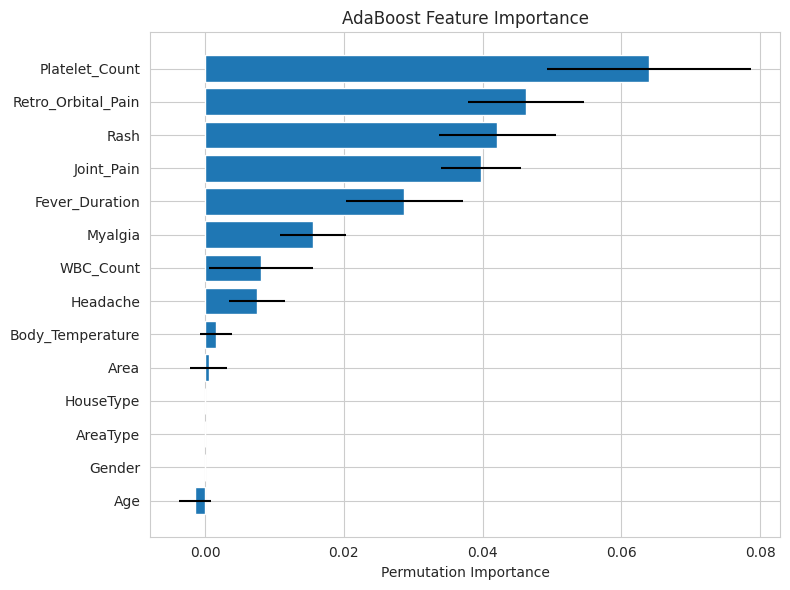

AdaBoost feature-importance figure saved successfully!


In [45]:

from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd

# Get the trained AdaBoost model
ada_model = final_models["AdaBoost"]

# Calculate permutation importance
importance_result = permutation_importance(
    ada_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

# Sort features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

# Plot
plt.figure(figsize=(8, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.xlabel("Permutation Importance")
plt.title("AdaBoost Feature Importance")
plt.tight_layout()

# Save figure
plt.savefig(
    "paper_figures/adaboost_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("AdaBoost feature-importance figure saved successfully!")


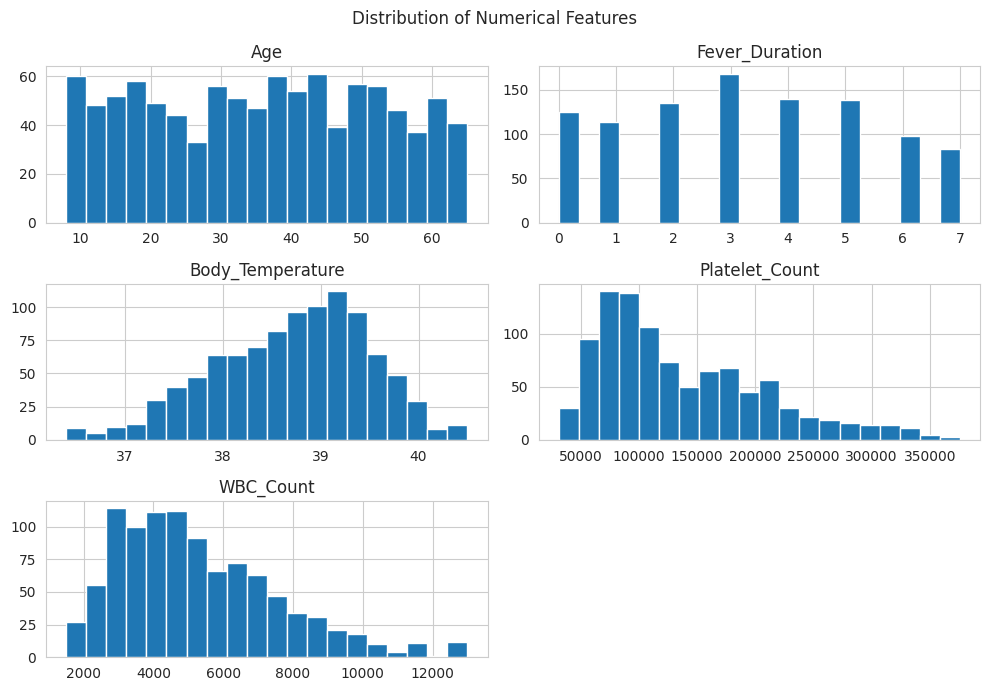

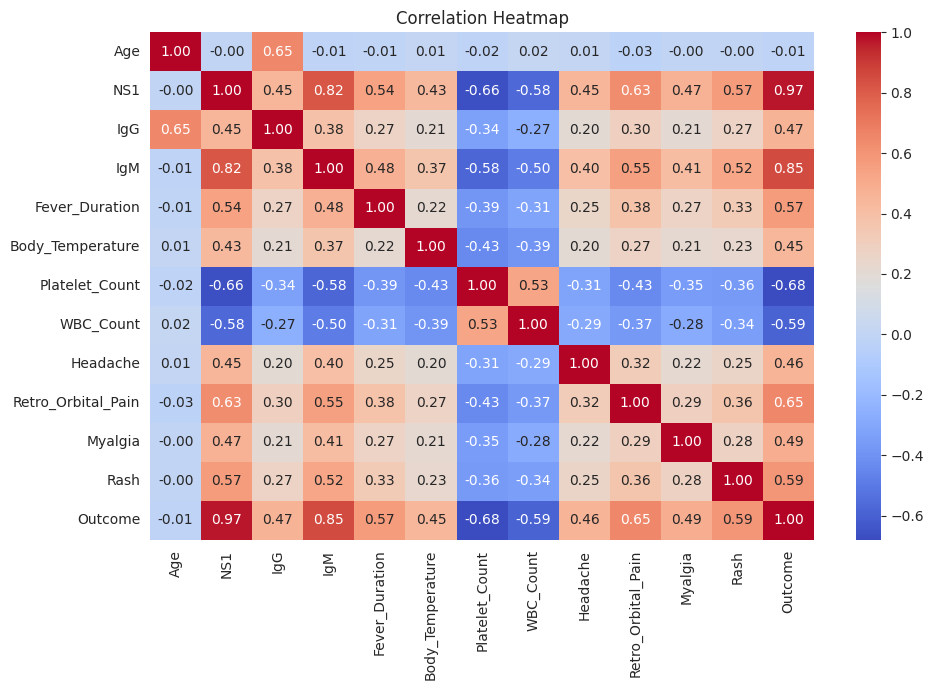

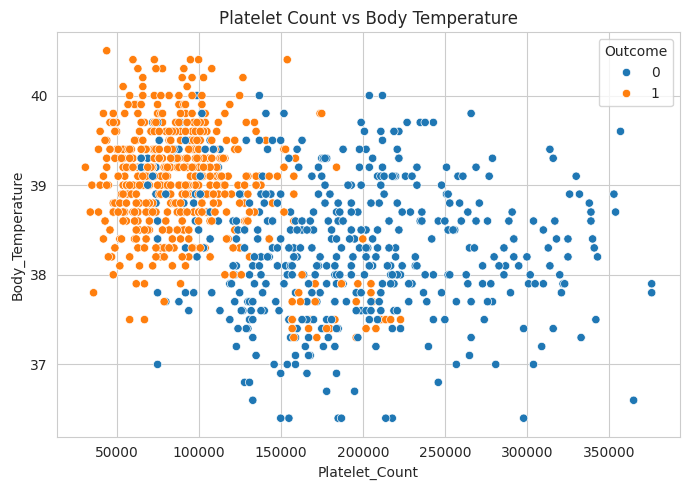

All EDA figures saved successfully!


In [46]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the original dataset
df = pd.read_csv("/content/Dengue dataset.csv")

# 1. Numerical feature distributions
numeric_cols = [
    "Age",
    "Fever_Duration",
    "Body_Temperature",
    "Platelet_Count",
    "WBC_Count"
]

df[numeric_cols].hist(figsize=(10, 7), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.savefig(
    "paper_figures/eda_histograms.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(
    "paper_figures/eda_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 3. Platelet count vs body temperature
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Platelet_Count",
    y="Body_Temperature",
    hue="Outcome"
)
plt.title("Platelet Count vs Body Temperature")
plt.tight_layout()
plt.savefig(
    "paper_figures/eda_platelet_temperature.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("All EDA figures saved successfully!")


In [48]:

import os
import zipfile
from google.colab import files

# ZIP filename
zip_filename = "Dengue_Paper_Figures.zip"

# Check saved figures
figure_files = [
    f for f in os.listdir("paper_figures")
    if f.lower().endswith(".png")
]

print("Figures found:", len(figure_files))
for f in sorted(figure_files):
    print("-", f)

# Create ZIP archive
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in figure_files:
        filepath = os.path.join("paper_figures", filename)
        zipf.write(filepath, arcname=filename)

print("\nZIP file created successfully!")

# Download ZIP
files.download(zip_filename)


Figures found: 7
- adaboost_feature_importance.png
- confusion_matrices.png
- eda_correlation_heatmap.png
- eda_histograms.png
- eda_platelet_temperature.png
- roc_curves.png
- target_distribution.png

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>